In [251]:
objetos = [
    {"nombre": "Lingote de oro", "peso": 5, "valor": 50},
    {"nombre": "Diamante", "peso": 2, "valor": 40},
    {"nombre": "Mapa antiguo", "peso": 1, "valor": 15},
    {"nombre": "Cáliz de plata", "peso": 4, "valor": 30},
    {"nombre": "Corona de bronce", "peso": 3, "valor": 20},
    {"nombre": "Espada legendaria", "peso": 6, "valor": 45},
    {"nombre": "Escudo de acero", "peso": 7, "valor": 35},
    {"nombre": "Poción de curación", "peso": 1, "valor": 10},
    {"nombre": "Pergamino mágico", "peso": 2, "valor": 25},
    {"nombre": "Gema de zafiro", "peso": 3, "valor": 38},
    {"nombre": "Estatua de jade", "peso": 8, "valor": 60},
    {"nombre": "Brújula de bronce", "peso": 2, "valor": 18},
    {"nombre": "Collar de perlas", "peso": 2, "valor": 28},
    {"nombre": "Armadura ligera", "peso": 5, "valor": 32},
    {"nombre": "Reliquia mística", "peso": 4, "valor": 42},
    {"nombre": "Libro de hechizos", "peso": 3, "valor": 22},
    {"nombre": "Anillo de oro", "peso": 1, "valor": 30},
    {"nombre": "Daga oculta", "peso": 2, "valor": 14},
    {"nombre": "Cetro real", "peso": 6, "valor": 55},
    {"nombre": "Sello de cera", "peso": 1, "valor": 5}
]

capacidad_peso_mochila = 15

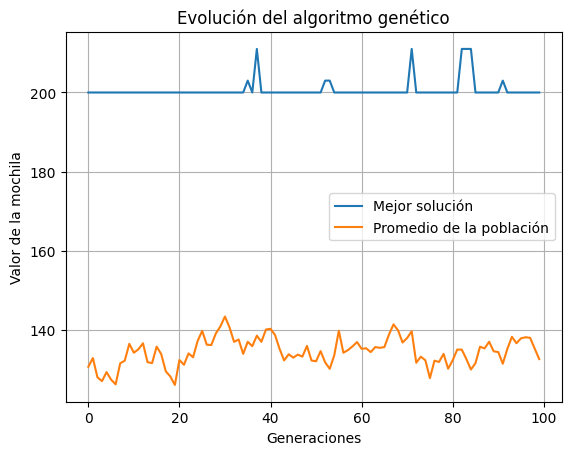

In [252]:
import random
import matplotlib.pyplot as plt

def aleatorios(val):
  aux_bin = [[] for n in range(val)]
  for n in range(val):
    for i in range(len(objetos)):
      binario = random.randint(0,1)
      aux_bin[n].append(binario)
  return aux_bin


def precio(obj):
  return sum(objetos[i]["valor"] for i in range(len(objetos)) if obj[i] == 1)

def peso(obj):
  return sum(objetos[i]["peso"] for i in range(len(objetos)) if obj[i] == 1)




def limpiar_datos(lista):
  nueva_lista = [i[:] for i in lista]
  for i in range(len(nueva_lista)):
    sol = nueva_lista[i]
    sol_peso = peso(sol)
    if sol_peso > 15:
      mejor = [precio(sol), sol_peso, sol[:]]
      while mejor[1] > 15:
        lista_aux = []
        for j in range(len(objetos)):
          if mejor[2][j] == 1:
            sol_aux = mejor[2][:]
            sol_aux[j] = 0
            lista_aux.append((precio(sol_aux), peso(sol_aux), sol_aux))
        if not lista_aux:
          break
        lista_aux = sorted(lista_aux, key=lambda x: x[0], reverse=True)
        mejor = list(lista_aux[0])
        if mejor[1] <= 15:
          nueva_lista[i] = mejor[2]
          break
  nueva_lista.sort()
  return nueva_lista




def repeticiones(lista):
  lista_ordenada = sorted(lista)
  lista_filtrada = []
  contador = 0
  anterior = None
  for j in lista_ordenada:
    if j == anterior:
      contador += 1
    else:
      anterior = j
      contador = 1
    if contador <= 4:
      lista_filtrada.append(j)
  return lista_filtrada




def torneo(val,lista):
  lista2 = repeticiones(lista)
  nueva_bin = []
  k = len(lista2)
  lista2.extend(i for i in limpiar_datos(aleatorios(val-k)))
  aux_lista = []
  for i in lista2:
    aux_lista.append((precio(i),i))
  privi = int(len(aux_lista)/5)
  aux = []
  for i in range(privi):
    mejor = max(aux_lista, key=lambda x: x[0])
    aux.append(mejor)
    aux_lista.remove(mejor)
  maximo = len(lista2)
  nueva_bin.extend(i[1] for i in aux)
  par = 0
  impar = 1
  while impar < len(aux_lista):
    alea = random.randint(1, 4)
    if aux_lista[par][0] >= aux_lista[impar][0]:
      if alea != 4:
        nueva_bin.append(aux_lista[par][1])
      else:
        nueva_bin.append(aux_lista[impar][1])
    else:
      if alea != 4:
        nueva_bin.append(aux_lista[impar][1])
      else:
        nueva_bin.append(aux_lista[par][1])
    par += 2
    impar += 2
  if par < len(aux_lista):
    nueva_bin.append(aux_lista[par][1])
  return nueva_bin



def comparar(listaa):
  aux = []
  for i in listaa:
    aux.append((precio(i),i))
  return aux



def reproducción(lista):
  lista2 = comparar(lista)
  lista2.sort(reverse=True)
  comp = []
  for p, s in lista2:
    comp.append((p, s[:]))
  i = 0
  while i + 1 < len(lista2):
    ale = random.randint(0, 6)
    val_max = len(objetos) - ale
    ale2 = random.randint(0, val_max)
    for j in range(ale2, ale2 + ale):
      comp[i][1][j] = lista2[i+1][1][j]
      comp[i+1][1][j] = lista2[i][1][j]
    i += 2
  nueva_lista = [i[1][:] for i in comp]
  return nueva_lista



def ciclos(val, k):
  lista = limpiar_datos(aleatorios(val))
  mejores = []
  promedios = []

  for i in range(k):
    lista = verificación(lista)
    lista = torneo(val, lista)
    lista = reproducción(lista)
    lista = limpiar_datos(lista)

    datos = comparar(lista)

    mejores.append(max(datos, key=lambda x: x[0])[0])
    promedios.append(sum(x[0] for x in datos) / len(datos))

  return mejores, promedios


mejores, promedios = ciclos(100, 100)

plt.plot(mejores, label="Mejor solución")
plt.plot(promedios, label="Promedio de la población")

plt.xlabel("Generaciones")
plt.ylabel("Valor de la mochila")
plt.title("Evolución del algoritmo genético")
plt.legend()
plt.grid()
plt.show()

In [254]:
def ciclos(val, k):
  lista = limpiar_datos(aleatorios(val))
  for i in range(k):
    lista = repeticiones(lista)
    lista = torneo(val, lista)
    lista = reproducción(lista)
    lista = limpiar_datos(lista)
  return comparar(lista)

l = ciclos(1000,100)
l.sort(reverse=True)
l

[(211, [1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0]),
 (211, [1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0]),
 (211, [1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0]),
 (200, [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
 (200, [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
 (200, [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
 (200, [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
 (200, [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
 (196, [0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0]),
 (195, [1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0]),
 (195, [0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0]),
 (195, [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0]),
 (192, [0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0]),
 (191, [0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0]),
 (191, [0, 1, 0, 0, 

# Versión anterior

In [253]:
def verificación(lista2):
  nueva_bin = []
  for k in range(len(lista2)):
    total = 0
    for j in range(len(objetos)):
      if lista2[k][j] == 1:
        total += objetos[j]["peso"]

    if total <= 15:
      nueva_bin.append(lista2[k])

  return nueva_bin

def completar_listas(val, lista):
  existentes = {tuple(i) for i in lista}
  while len(lista) < val:
    faltan = val - len(lista)
    lista_sucia = aleatorios(faltan)
    nueva_lista = verificación(lista_sucia)

    for i in nueva_lista:
      combinacion = tuple(i)

      if combinacion not in existentes:
        lista.append(i)
        existentes.add(combinacion)

      if len(lista) == val:
        break

  return lista

def peso_valor(lista):
  lista_aux = []
  for k in range(len(lista)):
    total_peso = 0
    total_precio = 0
    for j in range(len(objetos)):
      if lista[k][j] == 1:
        total_peso += objetos[j]["peso"]
        total_precio += objetos[j]["valor"]
    if total_peso == 0:
      total_peso = 1
    valor = total_precio / total_peso
    lista_aux.append((valor, total_peso, total_precio, k))
  lista_aux.sort(reverse=True)
  return lista_aux

def lucha(lista2):
  lista_eval = peso_valor(lista2)
  bin_lista = lista2[:]
  max_val = int(len(lista_eval) / 2)
  for i in range(max_val):
    if lista_eval[i][0] > lista_eval[max_val - i][0]:
      if lista_eval[i][2] < lista_eval[max_val - i][2]:
        if (max_val - i) < len(bin_lista):
          bin_lista.pop(max_val - i)
  return bin_lista

def hijos(lista2):
  lista_lucha = lucha(lista2)
  if len(lista_lucha) % 2 != 0:
    lista_lucha = completar_listas(len(lista_lucha) + 1, lista_lucha)
  hijos_lista = [h[:] for h in lista_lucha]
  max_pad = int(len(hijos_lista) / 2)
  for i in range(0, max_pad - 2, 2):
    rand = random.randint(1, 6)
    max_mut = int(len(objetos)) - rand
    ini = random.randint(1, max_mut)
    for j in range(ini, ini + rand):
      if i == 0:
        hijos_lista[i][j] = lista_lucha[i][j]
        hijos_lista[i + 1][j] = lista_lucha[i][j]
      hijos_lista[i + 1][j] = lista_lucha[i][j]
      hijos_lista[i + 2][j] = lista_lucha[i][j]
  return hijos_lista

lista = aleatorios(100)
lista3 = verificación(lista)
completar_listas(100, lista3)


[[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0],
 [0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
 [0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1],
 [0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1],
 [1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1],
 [0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0],
 [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0],
 [1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1],
 [0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0],
 [0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0],
 [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,